# Task 1: Historical Rainfall Weather Pattern Exploration & Column Justification (2017–2024)

This notebook addresses **Task 1** of the project:
1. **Data Ingestion & Verification**: Load 2017–2024 rainfall datasets from data.gov.sg recorded at 5-minute intervals.
2. **Column Selection & Justification**: Analyze dataset features to identify and justify redundant, constant, or duplicate columns to drop before modeling.
3. **Weather Pattern Exploration & Visualizations**:
   - **Inter-annual patterns**: Rainfall changes across the years 2017–2024 (identifying anomalous dry/wet years, ENSO impact).
   - **Intra-annual patterns**: Seasonal variations across months, capturing the Northeast Monsoon, Southwest Monsoon, and Inter-monsoon periods.
   - **Diurnal patterns**: Hourly rainfall variations highlighting afternoon convective rainfall.
   - **Spatial distribution**: Station-wise geographical rainfall distribution across Singapore.


In [1]:
import os
import requests
import pandas as pd

# 1. List of dataset IDs (add more IDs here as needed)
dataset_ids = [
    "d_1990a5a1aeaf3dd243cf4dae294a61c4",  # 2017
    "d_024fb501ce7092b71bb713eaf54fa7eb",  # 2018
    "d_61995f092320e7155b7528050880b502",  # 2019
    "d_9e7de44094f876f6804b8b5bcee45c81",  # 2020
    "d_3b41598f74f1f11fc3430348fea51af5",  # 2021
    "d_42d64cc6c176ace1c52fbb40b9ede302",  # 2022
    "d_f864cc30d58b467db83659ad17c737bf",  # 2023
    "d_a0b69d3e02576a1fd0ab673e71f83507"   # 2024
]

# 2. Download all datasets (skips already downloaded files)
dataset_dir = "Dataset"
os.makedirs(dataset_dir, exist_ok=True)

downloaded_files = []

for ds_id in dataset_ids:
    file_path = os.path.join(dataset_dir, f"{ds_id}.csv")
    
    if not os.path.exists(file_path):
        print(f"Fetching URL for {ds_id}...")
        res = requests.get(f"https://api-open.data.gov.sg/v1/public/api/datasets/{ds_id}/poll-download").json()
        download_url = res["data"]["url"]
        
        print(f"Downloading {file_path}...")
        with requests.get(download_url, stream=True) as r:
            r.raise_for_status()
            with open(file_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    f.write(chunk)
                    
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"-> Saved {file_path} ({size_mb:.1f} MB)\n")
    else:
        print(f"{file_path} already exists locally, skipping download.")
        
    downloaded_files.append(file_path)

print("All dataset files ready!")

Dataset/d_1990a5a1aeaf3dd243cf4dae294a61c4.csv already exists locally, skipping download.
Dataset/d_024fb501ce7092b71bb713eaf54fa7eb.csv already exists locally, skipping download.
Dataset/d_61995f092320e7155b7528050880b502.csv already exists locally, skipping download.
Dataset/d_9e7de44094f876f6804b8b5bcee45c81.csv already exists locally, skipping download.
Dataset/d_3b41598f74f1f11fc3430348fea51af5.csv already exists locally, skipping download.
Dataset/d_42d64cc6c176ace1c52fbb40b9ede302.csv already exists locally, skipping download.
Dataset/d_f864cc30d58b467db83659ad17c737bf.csv already exists locally, skipping download.
Dataset/d_a0b69d3e02576a1fd0ab673e71f83507.csv already exists locally, skipping download.
All dataset files ready!


In [2]:
from pyspark.sql import SparkSession

# Initialize Spark session with 6GB memory for multi-year data
spark = (
    SparkSession.builder
    .appName("DataGovSG_Combine")
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    .config("spark.executor.memory", "6g")
    .config("spark.driver.maxResultSize", "2g")
    .getOrCreate()
)

# Load all CSVs and combine into a single Spark DataFrame
df = spark.read.csv(downloaded_files, header=True, inferSchema=True)

print(f"Combined dataset shape: ({df.count():,}, {len(df.columns)})")
df.limit(5).toPandas()


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/10 16:09:02 WARN Utils: Your hostname, Corneliuss-MacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 192.168.31.244 instead (on interface en0)
26/10/10 16:09:02 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/10 16:09:02 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applic

Combined dataset shape: (48,538,713, 12)


/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pan

,date,timestamp,update_timestamp,station_id,station_name,station_device_id,location_longitude,location_latitude,reading_update_timestamp,reading_value,reading_type,reading_unit
0,2017-01-01,2017-01-01 08:04:59,2017-01-01 08:13:31,S77,Alexandra Road,S77,103.8125,1.2937,2017-01-01 08:13:31,0.0,TB1 Rainfall 5 Minute Total F,mm
1,2017-01-01,2017-01-01 08:04:59,2017-01-01 08:13:31,S109,Ang Mo Kio Avenue 5,S109,103.8492,1.3764,2017-01-01 08:13:31,0.0,TB1 Rainfall 5 Minute Total F,mm
2,2017-01-01,2017-01-01 08:04:59,2017-01-01 08:13:31,S117,Banyan Road,S117,103.6790,1.2560,2017-01-01 08:13:31,0.0,TB1 Rainfall 5 Minute Total F,mm
3,2017-01-01,2017-01-01 08:04:59,2017-01-01 08:13:31,S55,Buangkok Green,S55,103.8860,1.3837,2017-01-01 08:13:31,0.0,TB1 Rainfall 5 Minute Total F,mm
4,2017-01-01,2017-01-01 08:04:59,2017-01-01 08:13:31,S64,Bukit Panjang Road,S64,103.7603,1.3824,2017-01-01 08:13:31,0.0,TB1 Rainfall 5 Minute Total F,mm


In [3]:
# Basic analysis for the df
from pyspark.sql import functions as F
import pandas as pd

# 1. Schema tree showing field names, data types, and nullable flags
print("=== PySpark Schema ===")
df.printSchema()

# 2. Compute comprehensive column statistics in a single distributed pass
# Includes: Data Type, Schema Nullable, Actual Null Count, Null %, Min, Max, and Distinct Count
total_rows = df.count()
schema_info = {f.name: (str(f.dataType), f.nullable) for f in df.schema.fields}

agg_exprs = []
for c, t in df.dtypes:
    is_null = (F.col(f'`{c}`').isNull() | F.isnan(f'`{c}`')) if t in ['double', 'float'] else F.col(f'`{c}`').isNull()
    agg_exprs.extend([
        F.count(F.when(is_null, 1)).alias(f'{c}__nulls'),
        F.min(f'`{c}`').cast('string').alias(f'{c}__min'),
        F.max(f'`{c}`').cast('string').alias(f'{c}__max'),
        F.approx_count_distinct(f'`{c}`').alias(f'{c}__distinct')
    ])

stats = df.agg(*agg_exprs).collect()[0].asDict()

summary_records = []
for c, t in df.dtypes:
    null_count = stats[f'{c}__nulls']
    summary_records.append({
        'Column': c,
        'Data Type': schema_info[c][0],
        'Schema Nullable': schema_info[c][1],
        'Null Count': null_count,
        'Null %': round((null_count / total_rows) * 100, 2),
        'Min Value': stats[f'{c}__min'],
        'Max Value': stats[f'{c}__max'],
        'Approx Distinct': stats[f'{c}__distinct']
    })

summary_df = pd.DataFrame(summary_records)

print(f"\n=== Column Summary Table (Total Rows: {total_rows:,}) ===")
display(summary_df)


=== PySpark Schema ===
root
 |-- date: date (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- update_timestamp: timestamp (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: double (nullable = true)
 |-- location_latitude: double (nullable = true)
 |-- reading_update_timestamp: timestamp (nullable = true)
 |-- reading_value: double (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)



26/10/10 16:09:32 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.



=== Column Summary Table (Total Rows: 48,538,713) ===


,Column,Data Type,Schema Nullable,Null Count,Null %,Min Value,Max Value,Approx Distinct
0,date,DateType(),True,0,0.0,2017-01-01,2024-12-31,2704
1,timestamp,TimestampType(),True,0,0.0,2017-01-01 08:04:59,2024-12-31 23:55:00,765265
2,update_timestamp,TimestampType(),True,0,0.0,2017-01-01 08:13:31,2025-01-01 00:00:25,799587
3,station_id,StringType(),True,0,0.0,S06,S97,89
4,station_name,StringType(),True,0,0.0,Admiralty Road West,Yishun Ring Road,116
5,station_device_id,StringType(),True,0,0.0,S06,S97,89
6,location_longitude,DoubleType(),True,0,0.0,103.61843,104.0307,93
7,location_latitude,DoubleType(),True,0,0.0,1.189,1.45817,91
8,reading_update_timestamp,TimestampType(),True,0,0.0,2017-01-01 08:13:31,2025-01-01 00:00:25,830450
9,reading_value,DoubleType(),True,0,0.0,0.0,37.2,508


In [4]:
# === Analysis & Justification for Dropping Irrelevant Columns ===
from pyspark.sql import functions as F

# --- 1. Justify dropping reading_type and reading_unit ---
# Check if they contain only 1 constant value across all rows (zero variance)
print("1. Unique values in reading_type and reading_unit:")
df.select("reading_type", "reading_unit").distinct().show(truncate=False)

# --- 2. Justify dropping station_device_id vs station_id ---
# Check if station_device_id maps 1-to-1 (is completely identical) to station_id
mismatch_count = df.filter(F.col("station_id") != F.col("station_device_id")).count()
print(f"2. Mismatches between station_id and station_device_id: {mismatch_count} (100% identical mapping)")

# --- 3. Justify dropping station_name vs station_id ---
# Check unique counts and mapping consistency
n_ids = df.select("station_id").distinct().count()
n_names = df.select("station_name").distinct().count()
print(f"3. Distinct station_id: {n_ids} | Distinct station_name: {n_names}")

# Verify that each station_id maps to exactly 1 station_name
id_to_multi_names = df.groupBy("station_id").agg(F.countDistinct("station_name").alias("name_count")).filter("name_count > 1").count()
print(f"   station_ids with >1 station_name: {id_to_multi_names} (Every ID maps to exactly 1 Name)")

# Show collision: Upper Changi Road North contains 2 distinct stations (S24 & S24B)
print("   Colliding station_names mapping to multiple station_ids:")
df.groupBy("station_name").agg(F.countDistinct("station_id").alias("id_count")).filter("id_count > 1").show(truncate=False)

# --- 5. Drop all justified irrelevant/redundant columns ---
cols_to_drop = ["reading_type", "reading_unit", "station_device_id", "station_name", "update_timestamp", "reading_update_timestamp"]
df = df.drop(*cols_to_drop)

print(f"Dropped columns: {cols_to_drop}")
print(f"Remaining columns ({len(df.columns)}): {df.columns}")


1. Unique values in reading_type and reading_unit:


+-----------------------------+------------+
|reading_type                 |reading_unit|
+-----------------------------+------------+
|TB1 Rainfall 5 Minute Total F|mm          |
+-----------------------------+------------+



2. Mismatches between station_id and station_device_id: 0 (100% identical mapping)


3. Distinct station_id: 91 | Distinct station_name: 117


   station_ids with >1 station_name: 26 (Every ID maps to exactly 1 Name)
   Colliding station_names mapping to multiple station_ids:


+-----------------------+--------+
|station_name           |id_count|
+-----------------------+--------+
|Upper Changi Road North|2       |
+-----------------------+--------+

Dropped columns: ['reading_type', 'reading_unit', 'station_device_id', 'station_name', 'update_timestamp', 'reading_update_timestamp']
Remaining columns (6): ['date', 'timestamp', 'station_id', 'location_longitude', 'location_latitude', 'reading_value']


In [5]:
# Drop redundant date column and decompose timestamp
if "date" in df.columns:
    df = df.drop("date")
    print("Dropped column: ['date']")

# Decompose timestamp into year, month, day, hour, and minute
df = (df
    .withColumn("year", F.year("timestamp"))
    .withColumn("month", F.month("timestamp"))
    .withColumn("day", F.dayofmonth("timestamp"))
    .withColumn("hour", F.hour("timestamp"))
    .withColumn("minute", F.minute("timestamp"))  # useful since readings are taken every 5 mins
)

print(f"Current columns ({len(df.columns)}): {df.columns}")
df.select("timestamp", "year", "month", "day", "hour", "minute", "station_id", "reading_value").limit(5).toPandas()


Dropped column: ['date']
Current columns (10): ['timestamp', 'station_id', 'location_longitude', 'location_latitude', 'reading_value', 'year', 'month', 'day', 'hour', 'minute']


/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pan

,timestamp,year,month,day,hour,minute,station_id,reading_value
0,2017-01-01 08:04:59,2017,1,1,8,4,S77,0.0
1,2017-01-01 08:04:59,2017,1,1,8,4,S109,0.0
2,2017-01-01 08:04:59,2017,1,1,8,4,S117,0.0
3,2017-01-01 08:04:59,2017,1,1,8,4,S55,0.0
4,2017-01-01 08:04:59,2017,1,1,8,4,S64,0.0


In [6]:
# Distribution of reading_value (Zero vs Positive Rainfall)
from pyspark.sql import functions as F
import pandas as pd

# 1. Calculate overall zero vs positive breakdown
stats = df.agg(
    F.count("*").alias("total_count"),
    F.count(F.when(F.col("reading_value") == 0, 1)).alias("zero_count"),
    F.count(F.when(F.col("reading_value") > 0, 1)).alias("positive_count")
).collect()[0].asDict()

total = stats["total_count"]
zeros = stats["zero_count"]
positives = stats["positive_count"]

distribution_df = pd.DataFrame([
    {"Category": "Zero Rainfall (0.0 mm)", "Count": f"{zeros:,}", "Percentage": f"{(zeros / total) * 100:.2f}%"},
    {"Category": "Positive Rainfall (> 0.0 mm)", "Count": f"{positives:,}", "Percentage": f"{(positives / total) * 100:.2f}%"},
    {"Category": "Total", "Count": f"{total:,}", "Percentage": "100.00%"}
])

print("=== Reading Value Breakdown ===")
display(distribution_df)

# 2. Summary statistics for non-zero rainfall events (when it actually rained)
print("\n=== Summary Statistics for Non-Zero Rainfall (mm) ===")
df.filter(F.col("reading_value") > 0).select("reading_value").summary(
    "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
).show()


=== Reading Value Breakdown ===


,Category,Count,Percentage
0,Zero Rainfall (0.0 mm),"47,121,730",97.08%
1,Positive Rainfall (> 0.0 mm),"1,416,983",2.92%
2,Total,"48,538,713",100.00%



=== Summary Statistics for Non-Zero Rainfall (mm) ===


+-------+------------------+
|summary|     reading_value|
+-------+------------------+
|  count|           1416983|
|   mean|0.8667797915996425|
| stddev|1.3641788640085821|
|    min|             0.197|
|    25%|               0.2|
|    50%|             0.204|
|    75%|               0.8|
|    max|              37.2|
+-------+------------------+



In [7]:
# Rain distribution aggregated by various time windows (Year, Month, Day, Hour)
from pyspark.sql import functions as F

# Reusable aggregation function for temporal grouping
def aggregate_rain_by(group_col):
    return (
        df.groupBy(group_col)
        .agg(
            F.count("*").alias("total_readings"),
            F.round(F.sum("reading_value"), 1).alias("total_rainfall_mm"),
            F.round(F.mean("reading_value"), 3).alias("avg_rainfall_mm"),
            F.round(F.mean(F.when(F.col("reading_value") > 0, 1.0).otherwise(0.0)) * 100, 2).alias("rain_probability_pct"),
            F.round(F.avg(F.when(F.col("reading_value") > 0, F.col("reading_value"))), 2).alias("avg_intensity_when_raining_mm"),
            F.max("reading_value").alias("max_single_reading_mm")
        )
        .orderBy(group_col)
        .toPandas()
    )

# 1. Grouped by Year
yearly_rain = aggregate_rain_by("year")

# 2. Grouped by Month (Monsoon / Seasonal patterns)
monthly_rain = aggregate_rain_by("month")

# 3. Grouped by Hour of Day (Diurnal / Afternoon thunderstorm cycle)
hourly_rain = aggregate_rain_by("hour")

# 4. Grouped by Day of Month
daily_rain = aggregate_rain_by("day")

/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully suppor

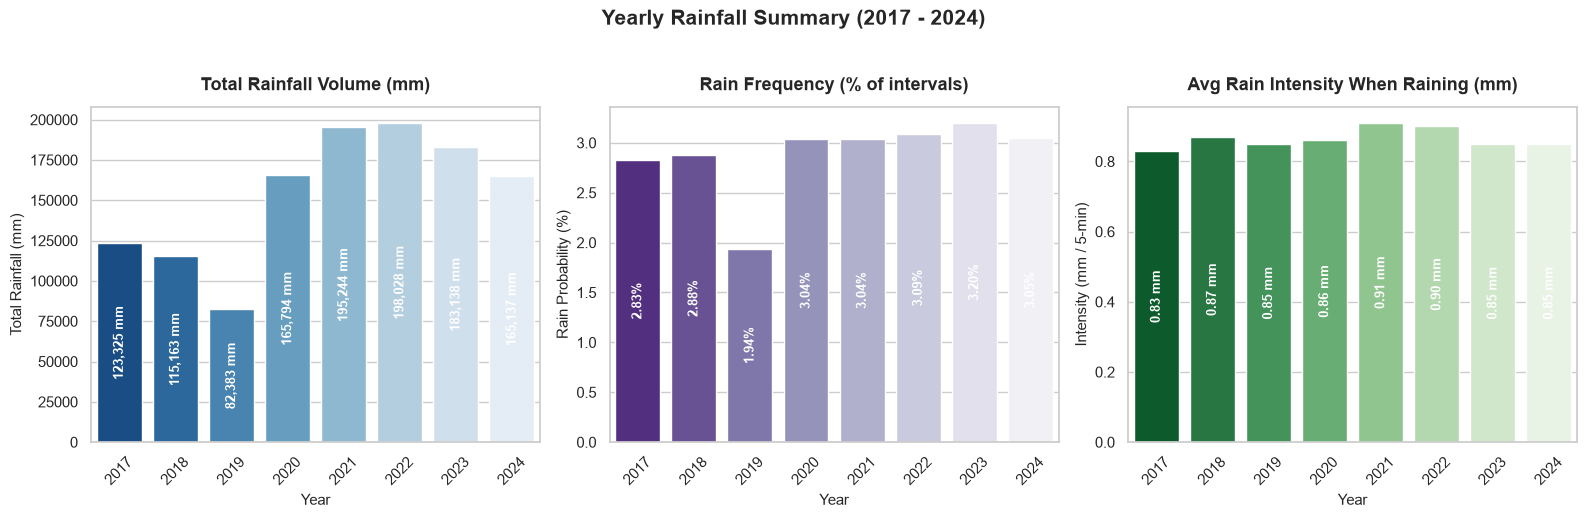

/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


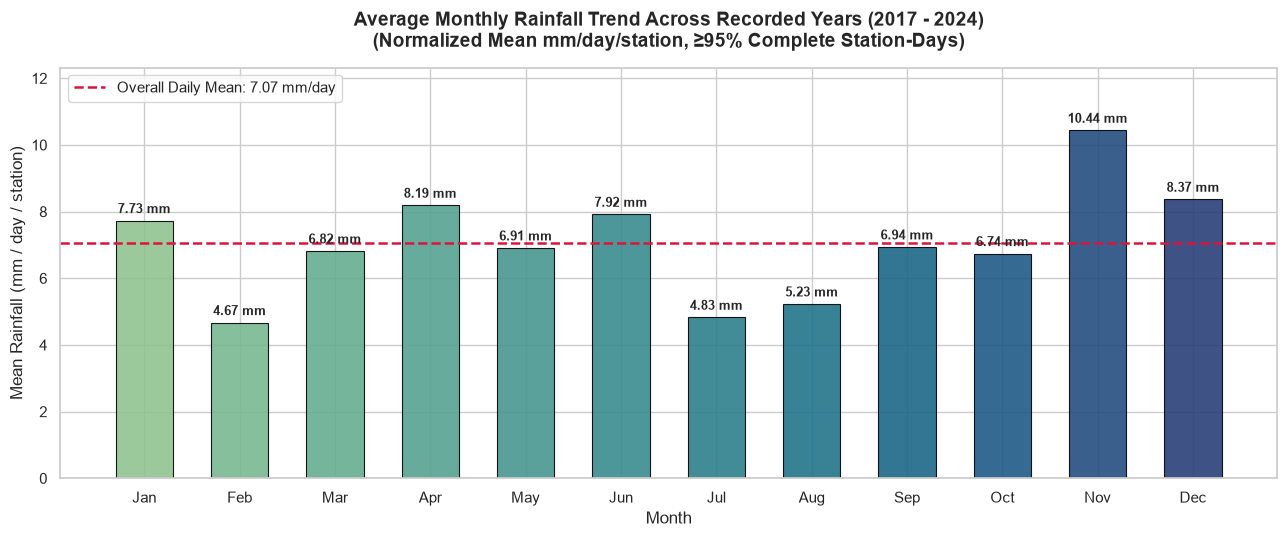

In [8]:
# === Visualizing Yearly & Monthly Rainfall Patterns ===
import matplotlib.pyplot as plt
import seaborn as sns
import calendar
from pyspark.sql import functions as F

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11})

# ------------------------------------------------------------
# 1. Annual Summary Metrics: Across All Available Years
# (Uses yearly_rain from the previous cell)
# ------------------------------------------------------------
yearly_rain_plot = yearly_rain.copy()
yearly_rain_plot["year_str"] = yearly_rain_plot["year"].astype(str)
n_years = len(yearly_rain_plot)
min_year = yearly_rain_plot["year"].min()
max_year = yearly_rain_plot["year"].max()
rot = 90 if n_years > 3 else 0

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel A: Total Rainfall
bars1 = sns.barplot(
    data=yearly_rain_plot, x="year_str", y="total_rainfall_mm",
    hue="year_str", palette=sns.color_palette("Blues_r", n_colors=n_years), ax=axes[0], legend=False
)
axes[0].set_title("Total Rainfall Volume (mm)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Year", fontsize=11)
axes[0].set_ylabel("Total Rainfall (mm)", fontsize=11)
if n_years > 4:
    axes[0].tick_params(axis="x", rotation=45)
for p in bars1.patches:
    h = p.get_height()
    if h > 0:
        label = f"{h/1e6:.2f}M mm" if h >= 1e6 else f"{h:,.0f} mm"
        axes[0].annotate(label, (p.get_x() + p.get_width() / 2., h * 0.5),
                         ha="center", va="center", color="white", fontweight="bold", fontsize=9, rotation=rot)

# Panel B: Rain Frequency (% of 5-min intervals with rain)
bars2 = sns.barplot(
    data=yearly_rain_plot, x="year_str", y="rain_probability_pct",
    hue="year_str", palette=sns.color_palette("Purples_r", n_colors=n_years), ax=axes[1], legend=False
)
axes[1].set_title("Rain Frequency (% of intervals)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Year", fontsize=11)
axes[1].set_ylabel("Rain Probability (%)", fontsize=11)
if n_years > 4:
    axes[1].tick_params(axis="x", rotation=45)
for p in bars2.patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f"{h:.2f}%", (p.get_x() + p.get_width() / 2., h * 0.5),
                         ha="center", va="center", color="white", fontweight="bold", fontsize=9, rotation=rot)

# Panel C: Rain Intensity when it does rain
bars3 = sns.barplot(
    data=yearly_rain_plot, x="year_str", y="avg_intensity_when_raining_mm",
    hue="year_str", palette=sns.color_palette("Greens_r", n_colors=n_years), ax=axes[2], legend=False
)
axes[2].set_title("Avg Rain Intensity When Raining (mm)", fontsize=13, fontweight="bold", pad=12)
axes[2].set_xlabel("Year", fontsize=11)
axes[2].set_ylabel("Intensity (mm / 5-min)", fontsize=11)
if n_years > 4:
    axes[2].tick_params(axis="x", rotation=45)
for p in bars3.patches:
    h = p.get_height()
    if h > 0:
        axes[2].annotate(f"{h:.2f} mm", (p.get_x() + p.get_width() / 2., h * 0.5),
                         ha="center", va="center", color="white", fontweight="bold", fontsize=9, rotation=rot)

title_range = f"{min_year} - {max_year}" if min_year != max_year else f"{min_year}"
plt.suptitle(f"Yearly Rainfall Summary ({title_range})", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. Average Monthly Rainfall Trend Across All Recorded Years
# ------------------------------------------------------------
# Applied data quality filtering & normalization from task1_monthly_rainfall.py:
# - Filter out anomalous/incomplete station-days (<95% coverage, timestamp duplicates)
# - Normalize to mean mm per day per station rather than raw accumulated sum

EXPECTED_READINGS_PER_DAY = 288
MIN_READINGS_PER_DAY = 274  # 95% daily completeness threshold

# 1. Filter valid non-negative readings and extract calendar date
invalid_condition = (
    F.col("station_id").isNull()
    | F.col("timestamp").isNull()
    | F.col("reading_value").isNull()
    | F.isnan("reading_value")
    | (F.col("reading_value") < 0)
)
valid_df = df.filter(~invalid_condition).withColumn("date", F.to_date("timestamp"))

# 2. Station-daily totals and completeness tracking
daily_station = (
    valid_df.groupBy("station_id", "date")
    .agg(
        F.sum("reading_value").alias("daily_rainfall_mm"),
        F.count("*").alias("n_readings"),
        F.countDistinct("timestamp").alias("n_unique_timestamps")
    )
    .withColumn("year", F.year("date"))
    .withColumn("month", F.month("date"))
)

# 3. Filter complete station-days: >= 95% coverage (274 to 288) and no duplicate timestamps
complete_daily = daily_station.filter(
    (F.col("n_unique_timestamps") >= MIN_READINGS_PER_DAY)
    & (F.col("n_unique_timestamps") <= EXPECTED_READINGS_PER_DAY)
    & (F.col("n_readings") == F.col("n_unique_timestamps"))
)

# 4. Monthly aggregation by year (each eligible station-day has equal weight)
monthly_by_year = (
    complete_daily.groupBy("year", "month")
    .agg(
        F.avg("daily_rainfall_mm").alias("mean_daily_rainfall_mm"),
        F.count("*").alias("complete_station_days"),
        F.countDistinct("station_id").alias("n_stations")
    )
)

# 5. Climatological monthly pattern across recorded years (equal weight per year)
monthly_avg = (
    monthly_by_year.groupBy("month")
    .agg(
        F.round(F.avg("mean_daily_rainfall_mm"), 2).alias("avg_rainfall_mm"),
        F.round(F.stddev("mean_daily_rainfall_mm"), 2).alias("std_rainfall_mm")
    )
    .orderBy("month")
    .toPandas()
)

monthly_avg["month_name"] = monthly_avg["month"].apply(lambda m: calendar.month_abbr[m])
overall_monthly_mean = monthly_avg["avg_rainfall_mm"].mean()

# 6. Plot Average Monthly Rainfall (Mean mm / day / station)
fig, ax = plt.subplots(figsize=(13, 5.5))
bars = ax.bar(
    monthly_avg["month_name"],
    monthly_avg["avg_rainfall_mm"],
    color=sns.color_palette("crest", n_colors=12),
    edgecolor="black",
    linewidth=0.8,
    width=0.6,
    alpha=0.9
)

# Reference line for overall daily mean
ax.axhline(
    overall_monthly_mean,
    color="crimson",
    linestyle="--",
    linewidth=1.8,
    label=f"Overall Daily Mean: {overall_monthly_mean:.2f} mm/day"
)

# Annotate each bar with rainfall value
for bar, val in zip(bars, monthly_avg["avg_rainfall_mm"]):
    h = bar.get_height()
    label = f"{val:.2f} mm"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h + (overall_monthly_mean * 0.02),
        label,
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

title_text = f"Average Monthly Rainfall Trend Across Recorded Years ({title_range})\n(Normalized Mean mm/day/station, ≥95% Complete Station-Days)"
ax.set_title(
    title_text,
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Mean Rainfall (mm / day / station)", fontsize=12)
ax.set_ylim(0, max(monthly_avg["avg_rainfall_mm"]) * 1.18)
ax.legend(frameon=True, facecolor="white", loc="upper left")
plt.tight_layout()
plt.show()


/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


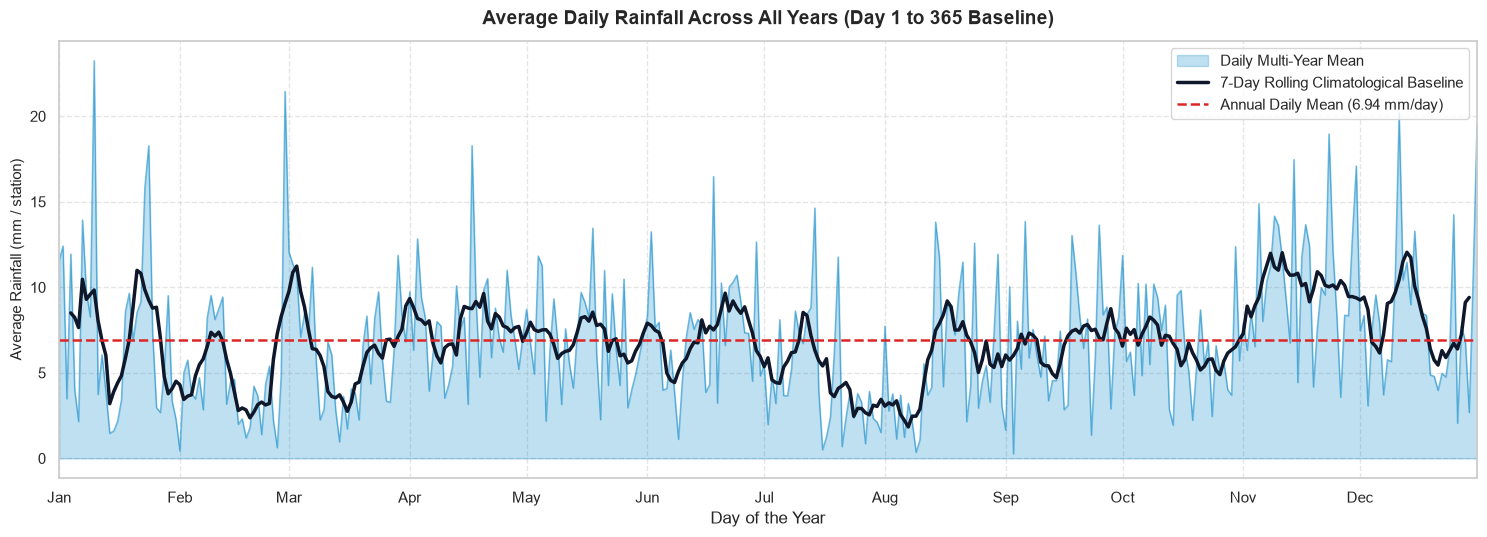

In [9]:
# === Average Daily Rainfall Across All Years (Day 1 to 365) ===
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F
import pandas as pd

# 1. Ensure day_of_year column exists
if "day_of_year" not in df.columns:
    df = df.withColumn("day_of_year", F.dayofyear("timestamp"))

# 2. Aggregate daily rainfall per station for each (year, day_of_year)
# Normalizes by active stations per day
daily_by_year = (
    df.groupBy("year", "day_of_year")
    .agg((F.sum("reading_value") / F.countDistinct("station_id")).alias("daily_rainfall_mm"))
    .orderBy("year", "day_of_year")
    .toPandas()
)

# 3. Compute multi-year average for each day of the year (Day 1 to 365)
multi_year_avg = (
    daily_by_year.groupby("day_of_year")["daily_rainfall_mm"]
    .mean()
    .reset_index()
    .rename(columns={"daily_rainfall_mm": "avg_rainfall_mm"})
)
multi_year_avg["rolling_7d"] = multi_year_avg["avg_rainfall_mm"].rolling(window=7, center=True).mean()

# Calculate overall daily mean across the entire year
overall_mean = multi_year_avg["avg_rainfall_mm"].mean()

# Month markers for x-axis reference (approximate day-of-year for 1st of each month)
month_ticks = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 4. Plot Average Daily Rainfall with Mean Reference Line
fig, ax = plt.subplots(figsize=(15, 5.5))

# Shaded area + line for multi-year daily average
ax.fill_between(multi_year_avg["day_of_year"], multi_year_avg["avg_rainfall_mm"], color="#0284c7", alpha=0.25, label="Daily Multi-Year Mean")
ax.plot(multi_year_avg["day_of_year"], multi_year_avg["avg_rainfall_mm"], color="#0284c7", alpha=0.5, linewidth=1)
ax.plot(multi_year_avg["day_of_year"], multi_year_avg["rolling_7d"], color="#0f172a", linewidth=2.5, label="7-Day Rolling Climatological Baseline")

# Horizontal line for annual mean rainfall
ax.axhline(overall_mean, color="#dc2626", linestyle="--", linewidth=1.8, label=f"Annual Daily Mean ({overall_mean:.2f} mm/day)")

ax.set_title("Average Daily Rainfall Across All Years (Day 1 to 365 Baseline)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Day of the Year", fontsize=12)
ax.set_ylabel("Average Rainfall (mm / station)", fontsize=11)
ax.set_xticks(month_ticks)
ax.set_xticklabels(month_labels)
ax.set_xlim(1, 365)
ax.legend(loc="upper right", frameon=True)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


=== 5-Minute Rainfall Zero vs. Non-Zero Summary ===
Total Readings:         48,538,713
Zero Readings (0.0 mm):  47,121,730 (97.08%)
Non-Zero Readings:      1,416,983 (2.92%)


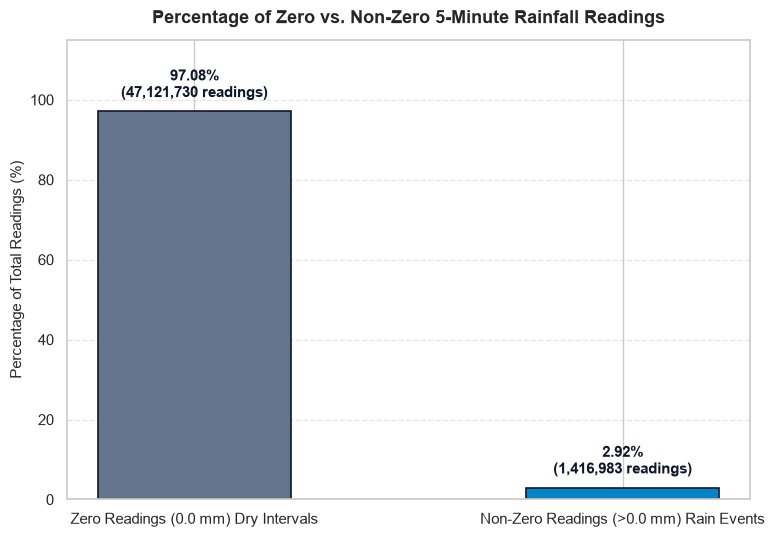

In [10]:
# === Bar Chart: Percentage of Zero vs. Non-Zero 5-Minute Rainfall Readings ===
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

# 1. Distributed Aggregation: Compute Zero vs. Non-Zero Counts
stats = df.agg(
    F.count("*").alias("total_readings"),
    F.count(F.when(F.col("reading_value") == 0, 1)).alias("zero_readings"),
    F.count(F.when(F.col("reading_value") > 0, 1)).alias("nonzero_readings")
).collect()[0].asDict()

total_count = stats["total_readings"]
zero_count = stats["zero_readings"]
nonzero_count = stats["nonzero_readings"]

zero_pct = (zero_count / total_count) * 100
nonzero_pct = (nonzero_count / total_count) * 100

print("=== 5-Minute Rainfall Zero vs. Non-Zero Summary ===")
print(f"Total Readings:         {total_count:,}")
print(f"Zero Readings (0.0 mm):  {zero_count:,} ({zero_pct:.2f}%)")
print(f"Non-Zero Readings:      {nonzero_count:,} ({nonzero_pct:.2f}%)")

# 2. Plot Percentage Bar Chart
fig, ax = plt.subplots(figsize=(8, 5.5))

categories = ["Zero Readings (0.0 mm) Dry Intervals", "Non-Zero Readings (>0.0 mm) Rain Events"]
percentages = [zero_pct, nonzero_pct]
counts = [zero_count, nonzero_count]
colors = ["#64748b", "#0284c7"]

bars = ax.bar(categories, percentages, color=colors, edgecolor="#0f172a", linewidth=1.2, width=0.45)

# Annotate each bar with percentage and absolute count
for bar, pct, count in zip(bars, percentages, counts):
    height = bar.get_height()
    label_text = f"""{pct:.2f}%
({count:,} readings)"""
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2.5,
        label_text,
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#0f172a"
    )

ax.set_title("Percentage of Zero vs. Non-Zero 5-Minute Rainfall Readings", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Percentage of Total Readings (%)", fontsize=11)
ax.set_ylim(0, 115)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


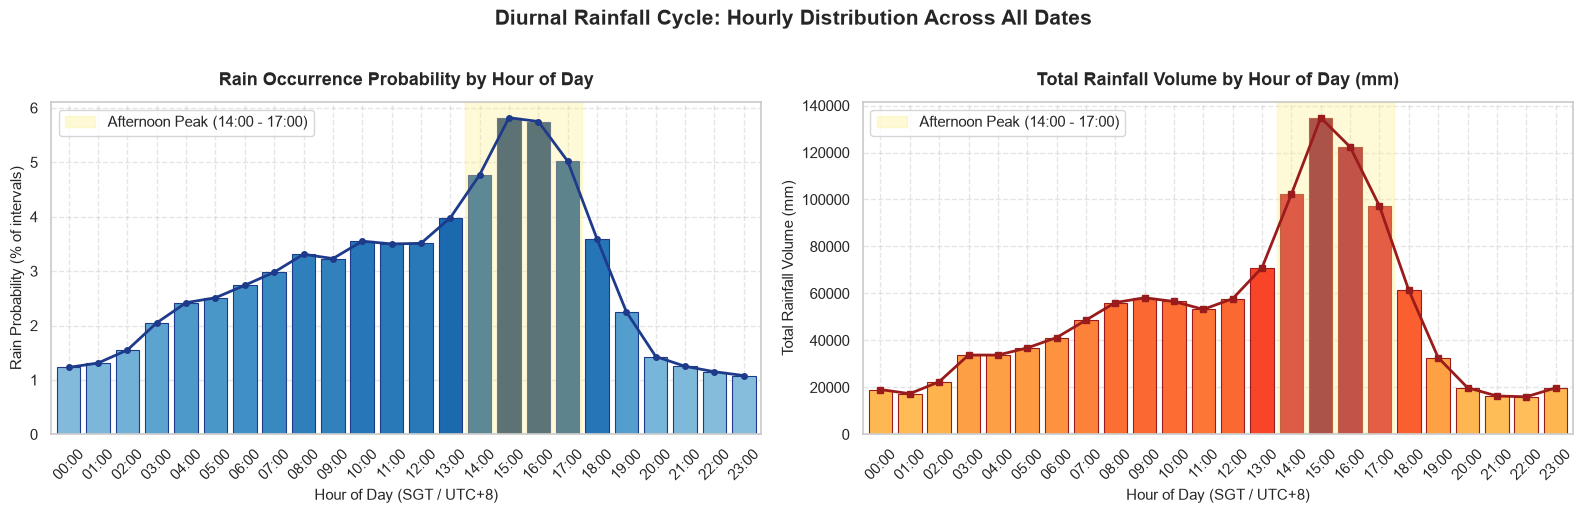

In [11]:
# === Visualizing Diurnal / Hourly Rainfall Patterns ===
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F
import pandas as pd

# 1. Ensure hourly aggregated data is available
if 'hourly_rain' not in globals() or hourly_rain is None:
    hourly_rain = (
        df.groupBy("hour")
        .agg(
            F.count("*").alias("total_readings"),
            F.round(F.sum("reading_value"), 1).alias("total_rainfall_mm"),
            F.round(F.mean("reading_value"), 3).alias("avg_rainfall_mm"),
            F.round(F.mean(F.when(F.col("reading_value") > 0, 1.0).otherwise(0.0)) * 100, 2).alias("rain_probability_pct"),
            F.round(F.avg(F.when(F.col("reading_value") > 0, F.col("reading_value"))), 2).alias("avg_intensity_when_raining_mm"),
            F.max("reading_value").alias("max_single_reading_mm")
        )
        .orderBy("hour")
        .toPandas()
    )

# 2. Create Dual-Panel Figure
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
hour_labels = [f"{h:02d}:00" for h in range(24)]

# ------------------------------------------------------------
# Panel 1: Rain Probability (% of 5-min intervals with rain)
# ------------------------------------------------------------
# Colormap gives darker blue to peak rain hours
norm_probs = hourly_rain["rain_probability_pct"] / hourly_rain["rain_probability_pct"].max()
prob_colors = plt.cm.Blues(0.3 + 0.7 * norm_probs)

bars1 = axes[0].bar(hourly_rain["hour"], hourly_rain["rain_probability_pct"], color=prob_colors, edgecolor="#1e3a8a", linewidth=0.8)
axes[0].plot(hourly_rain["hour"], hourly_rain["rain_probability_pct"], color="#1e3a8a", marker="o", markersize=4, linewidth=2)

# Highlight the 2 PM - 5 PM convective window
axes[0].axvspan(13.5, 17.5, color="#fef08a", alpha=0.35, label="Afternoon Peak (14:00 - 17:00)")

axes[0].set_title("Rain Occurrence Probability by Hour of Day", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Hour of Day (SGT / UTC+8)", fontsize=11)
axes[0].set_ylabel("Rain Probability (% of intervals)", fontsize=11)
axes[0].set_xticks(range(24))
axes[0].set_xticklabels(hour_labels, rotation=45)
axes[0].set_xlim(-0.6, 23.6)
axes[0].legend(loc="upper left", frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

# ------------------------------------------------------------
# Panel 2: Total Accumulated Rainfall (mm) by Hour
# ------------------------------------------------------------
norm_totals = hourly_rain["total_rainfall_mm"] / hourly_rain["total_rainfall_mm"].max()
total_colors = plt.cm.YlOrRd(0.25 + 0.75 * norm_totals)

bars2 = axes[1].bar(hourly_rain["hour"], hourly_rain["total_rainfall_mm"], color=total_colors, edgecolor="#991b1b", linewidth=0.8)
axes[1].plot(hourly_rain["hour"], hourly_rain["total_rainfall_mm"], color="#991b1b", marker="s", markersize=4, linewidth=2)

axes[1].axvspan(13.5, 17.5, color="#fef08a", alpha=0.35, label="Afternoon Peak (14:00 - 17:00)")

axes[1].set_title("Total Rainfall Volume by Hour of Day (mm)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Hour of Day (SGT / UTC+8)", fontsize=11)
axes[1].set_ylabel("Total Rainfall Volume (mm)", fontsize=11)
axes[1].set_xticks(range(24))
axes[1].set_xticklabels(hour_labels, rotation=45)
axes[1].set_xlim(-0.6, 23.6)
axes[1].legend(loc="upper left", frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Diurnal Rainfall Cycle: Hourly Distribution Across All Dates", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


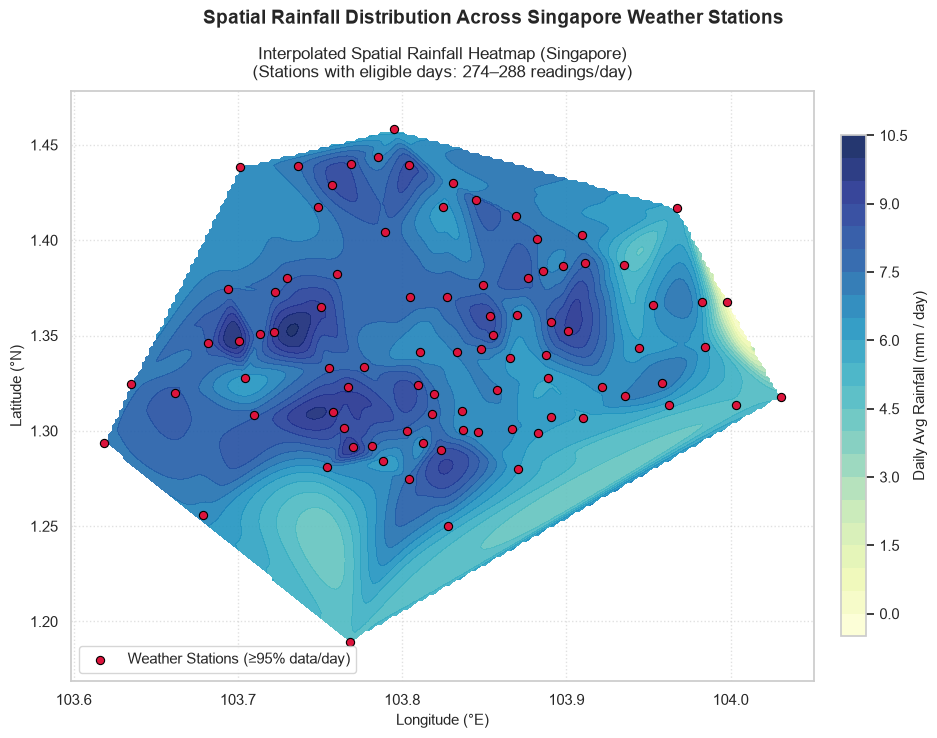

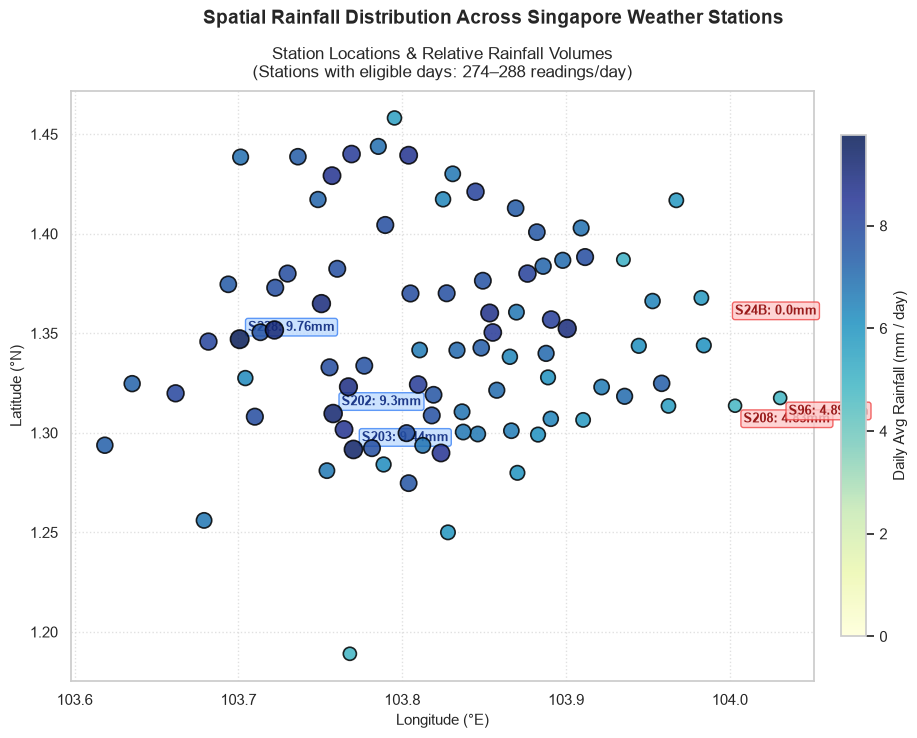

=== Top 5 Wettest Station Locations ===


,station_id,longitude,latitude,daily_avg_mm,rain_prob_pct,eligible_days
58,S228,103.70073,1.34703,9.76,3.45,1597
87,S203,103.77020,1.29164,9.44,3.36,1569
14,S202,103.75780,1.30968,9.30,3.43,948
43,S229,103.72195,1.35167,9.18,3.34,1613
73,S218,103.75065,1.36491,9.06,3.27,1615


=== Top 5 Driest Station Locations ===


,station_id,longitude,latitude,daily_avg_mm,rain_prob_pct,eligible_days
40,S24B,103.99800,1.3678,0.00,0.00,111
70,S208,104.00317,1.3136,4.83,2.17,1617
63,S96,104.03070,1.3175,4.89,2.47,104
4,S102,103.76800,1.1890,4.94,2.47,480
50,S29,103.93500,1.3870,5.12,2.16,1124


In [12]:
# === Spatial Rainfall Distribution (Heatmap & Station Locations) ===
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import griddata
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# 1. Minimum daily readings threshold (95% of 288 5-minute intervals = 274 readings)
# (Reference: task1_station_rainfall.py)
MIN_DAILY_READINGS = 274

# 2. Filter valid records and compute daily totals per station
valid = df.filter(
    F.col("station_id").isNotNull()
    & F.col("timestamp").isNotNull()
    & F.col("reading_value").isNotNull()
    & ~F.isnan("reading_value")
    & (F.col("reading_value") >= 0)
).withColumn("observation_date", F.to_date("timestamp"))

# Only include days that contain at least 95% of data (274 to 288 unique readings, no duplicates)
daily = (
    valid.groupBy("station_id", "observation_date")
    .agg(
        F.sum("reading_value").alias("daily_rainfall_mm"),
        F.count("*").alias("n_readings"),
        F.countDistinct("timestamp").alias("n_unique_timestamps"),
        F.sum(F.when(F.col("reading_value") > 0, 1).otherwise(0)).alias("rainy_intervals")
    )
    .filter(
        (F.col("n_unique_timestamps") >= MIN_DAILY_READINGS)
        & (F.col("n_unique_timestamps") <= 288)
        & (F.col("n_readings") == F.col("n_unique_timestamps"))
    )
    .withColumn("year", F.year("observation_date"))
    .filter(F.col("year").between(2017, 2024))
)

# 3. Station summaries: equal weight for each qualifying day
station_summary = daily.groupBy("station_id").agg(
    F.round(F.avg("daily_rainfall_mm"), 2).alias("daily_avg_mm"),
    F.round(F.sum("daily_rainfall_mm"), 1).alias("total_rainfall_mm"),
    F.round(F.sum("rainy_intervals") / F.sum("n_readings") * 100, 2).alias("rain_prob_pct"),
    F.count("*").alias("eligible_days"),
    F.countDistinct("year").alias("years_represented")
)

# 4. Representative station coordinates (most frequent location recorded, latest as tie-break)
location_rows = df.filter(
    F.col("station_id").isNotNull()
    & F.col("timestamp").isNotNull()
    & F.col("location_latitude").isNotNull()
    & F.col("location_longitude").isNotNull()
    & ~F.isnan("location_latitude")
    & ~F.isnan("location_longitude")
    & F.col("location_latitude").between(-90, 90)
    & F.col("location_longitude").between(-180, 180)
    & F.year("timestamp").between(2017, 2024)
)
locations = location_rows.groupBy("station_id", "location_latitude", "location_longitude").agg(
    F.count("*").alias("location_observations"),
    F.max("timestamp").alias("last_seen")
)
location_window = Window.partitionBy("station_id").orderBy(
    F.desc("location_observations"), F.desc("last_seen"),
    "location_latitude", "location_longitude"
)
representative_locations = locations.withColumn("rank", F.row_number().over(location_window)).filter(
    F.col("rank") == 1
).select(
    F.col("station_id"),
    F.col("location_longitude").alias("longitude"),
    F.col("location_latitude").alias("latitude")
)

# 5. Join summary metrics with representative coordinates into Pandas DataFrame
station_geo = (
    station_summary
    .join(representative_locations, "station_id", "inner")
    .toPandas()
)

# 6. 2D Spatial Grid Interpolation for Continuous Heatmap
lons = station_geo["longitude"].values
lats = station_geo["latitude"].values
rain_vals = station_geo["daily_avg_mm"].values

# Regular grid over Singapore's geographic bounding box
grid_x = np.linspace(lons.min() - 0.02, lons.max() + 0.02, 200)
grid_y = np.linspace(lats.min() - 0.02, lats.max() + 0.02, 200)
grid_x, grid_y = np.meshgrid(grid_x, grid_y)

# Interpolate using cubic spline with linear boundary fill
grid_z = griddata((lons, lats), rain_vals, (grid_x, grid_y), method="cubic")
grid_z_linear = griddata((lons, lats), rain_vals, (grid_x, grid_y), method="linear")
grid_z = np.where(np.isnan(grid_z), grid_z_linear, grid_z)

# ------------------------------------------------------------
# Plot 1: Continuous 2D Spatial Heatmap (Contour Map)
# ------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(10, 7.5))

contour = ax1.contourf(
    grid_x, grid_y, grid_z,
    levels=25, cmap="YlGnBu", alpha=0.9
)
cbar1 = fig1.colorbar(contour, ax=ax1, orientation="vertical", shrink=0.85, pad=0.03)
cbar1.set_label("Daily Avg Rainfall (mm / day)", fontsize=11)

# Overlay station markers on heatmap
ax1.scatter(
    lons, lats, c="crimson", edgecolor="black", s=35, linewidth=0.8,
    label="Weather Stations (≥95% data/day)", zorder=5
)
fig1.suptitle("Spatial Rainfall Distribution Across Singapore Weather Stations", fontsize=14, fontweight="bold", y=0.98)
ax1.set_title("Interpolated Spatial Rainfall Heatmap (Singapore)\n(Stations with eligible days: 274–288 readings/day)", fontsize=12, pad=10)
ax1.set_xlabel("Longitude (°E)", fontsize=11)
ax1.set_ylabel("Latitude (°N)", fontsize=11)
ax1.legend(loc="lower left", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Plot 2: Station Bubble Map with Key Station Annotations
# ------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(10, 7.5))

scatter = ax2.scatter(
    station_geo["longitude"], station_geo["latitude"],
    c=station_geo["daily_avg_mm"], s=station_geo["daily_avg_mm"] * 18,
    cmap="YlGnBu", edgecolor="black", linewidth=1.2, alpha=0.85, zorder=4
)
cbar2 = fig2.colorbar(scatter, ax=ax2, orientation="vertical", shrink=0.85, pad=0.03)
cbar2.set_label("Daily Avg Rainfall (mm / day)", fontsize=11)

# Annotate top 3 wettest and top 3 driest stations
top_wet = station_geo.nlargest(3, "daily_avg_mm")
top_dry = station_geo.nsmallest(3, "daily_avg_mm")

for _, row in top_wet.iterrows():
    ax2.annotate(
        f"{row['station_id']}: {row['daily_avg_mm']}mm",
        (row["longitude"], row["latitude"]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=9, fontweight="bold", color="#1e3a8a",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#bfdbfe", edgecolor="#3b82f6", alpha=0.8)
    )

for _, row in top_dry.iterrows():
    ax2.annotate(
        f"{row['station_id']}: {row['daily_avg_mm']}mm",
        (row["longitude"], row["latitude"]),
        xytext=(6, -12), textcoords="offset points",
        fontsize=9, fontweight="bold", color="#991b1b",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#fecaca", edgecolor="#ef4444", alpha=0.8)
    )

fig2.suptitle("Spatial Rainfall Distribution Across Singapore Weather Stations", fontsize=14, fontweight="bold", y=0.98)
ax2.set_title("Station Locations & Relative Rainfall Volumes\n(Stations with eligible days: 274–288 readings/day)", fontsize=12, pad=10)
ax2.set_xlabel("Longitude (°E)", fontsize=11)
ax2.set_ylabel("Latitude (°N)", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# 7. Tabular Summary of Top Wettest & Driest Locations
print("=== Top 5 Wettest Station Locations ===")
display(station_geo.sort_values(by="daily_avg_mm", ascending=False)[["station_id", "longitude", "latitude", "daily_avg_mm", "rain_prob_pct", "eligible_days"]].head(5))

print("=== Top 5 Driest Station Locations ===")
display(station_geo.sort_values(by="daily_avg_mm", ascending=True)[["station_id", "longitude", "latitude", "daily_avg_mm", "rain_prob_pct", "eligible_days"]].head(5))

=== 30-Minute Forward Window Summary ===
Total Complete Windows: 47,636,532
Zero-Rain Windows:      44,707,542 (93.85%)
Rainy Windows (> 0 mm): 2,928,990 (6.15%)


/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/corneliusaxeltjandra/Documents/Distributed DB/Project2/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)



=== Non-Zero Rainfall Empirical Percentiles (Model Threshold Candidates) ===
Quantile           | Threshold (mm)  | Rainfall Intensity Regime
---------------------------------------------------------------------------
20th Percentile    |       0.20 mm    | Trace / Very Light Rain (Drizzle)
40th Percentile    |       0.40 mm    | Light Rainfall
60th Percentile    |       1.00 mm    | Moderate Rainfall
80th Percentile    |       3.00 mm    | Heavy Convective Rainfall
99th Percentile    |      24.20 mm    | Torrential Downpour / Surge (Extreme Event)


findfont: Failed to find font weight semibold for Arial, now using 700.         


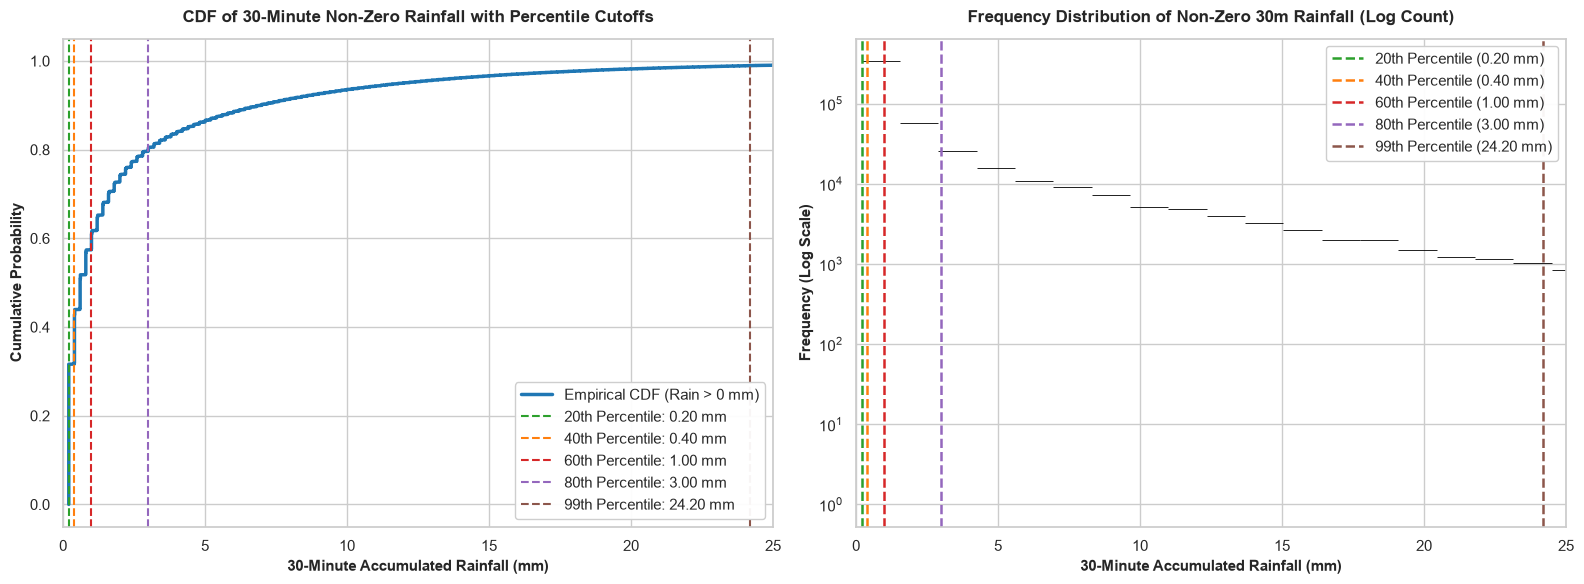

In [13]:
from pyspark.sql.window import Window
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# === 1. Calculate Forward 30-Minute Accumulated Rainfall ===
# A complete 30-minute window expects exactly 6 readings at 5-minute intervals.
# Adding a 60-second buffer [1, 1860s] accounts for clock jitter and transmission delays.
w_30m = (
    Window
    .partitionBy("station_id")
    .orderBy(F.col("timestamp").cast("long"))
    .rangeBetween(1, 1860)
)

df_target = (
    df
    .withColumn("next_30m_reading_count", F.count("reading_value").over(w_30m))
    .withColumn("next_30m_rainfall", F.round(F.sum("reading_value").over(w_30m), 2))
    .filter(F.col("next_30m_reading_count") == 6)  # Retain only complete, valid windows
)

# === 2. Isolate Non-Zero Rainfall Events ===
df_rainy = df_target.filter(F.col("next_30m_rainfall") > 0.0)

# Total vs Non-zero stats
total_windows = df_target.count()
rainy_windows = df_rainy.count()
zero_windows = total_windows - rainy_windows

print("=== 30-Minute Forward Window Summary ===")
print(f"Total Complete Windows: {total_windows:,}")
print(f"Zero-Rain Windows:      {zero_windows:,} ({zero_windows / total_windows * 100:.2f}%)")
print(f"Rainy Windows (> 0 mm): {rainy_windows:,} ({rainy_windows / total_windows * 100:.2f}%)")

# === 3. Calculate Empirical Percentiles (20th, 40th, 60th, 80th, 99th) ===
quantiles = [0.20, 0.40, 0.60, 0.80, 0.99]
percentiles = df_rainy.approxQuantile("next_30m_rainfall", quantiles, 0.001)

# Categorize and document the empirical thresholds
quantile_labels = ["20th Percentile", "40th Percentile", "60th Percentile", "80th Percentile", "99th Percentile"]
weather_types = [
    "Trace / Very Light Rain (Drizzle)",
    "Light Rainfall",
    "Moderate Rainfall",
    "Heavy Convective Rainfall",
    "Torrential Downpour / Surge (Extreme Event)"
]

threshold_dict = {}
print("\n=== Non-Zero Rainfall Empirical Percentiles (Model Threshold Candidates) ===")
print(f"{'Quantile':<18} | {'Threshold (mm)':<15} | {'Rainfall Intensity Regime'}")
print("-" * 75)
for q_lbl, val, w_type in zip(quantile_labels, percentiles, weather_types):
    threshold_dict[q_lbl] = round(val, 2)
    print(f"{q_lbl:<18} | {val:>10.2f} mm    | {w_type}")

# === 4. Visualize Empirical Distribution & Percentile Cutoffs ===
# Sample a representative subset for plotting (e.g. 500,000 non-zero records)
sample_ratio = min(1.0, 500000 / rainy_windows)
rain_sample_pd = df_rainy.sample(withReplacement=False, fraction=sample_ratio, seed=42).select("next_30m_rainfall").toPandas()

sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Cumulative Distribution Function (CDF)
sorted_vals = np.sort(rain_sample_pd["next_30m_rainfall"].values)
cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)

ax1.plot(sorted_vals, cdf, color="#1f77b4", linewidth=2.5, label="Empirical CDF (Rain > 0 mm)")
colors = ["#2ca02c", "#ff7f0e", "#d62728", "#9467bd", "#8c564b"]

for q_lbl, val, col in zip(quantile_labels, percentiles, colors):
    ax1.axvline(val, color=col, linestyle="--", linewidth=1.5, label=f"{q_lbl}: {val:.2f} mm")

ax1.set_title("CDF of 30-Minute Non-Zero Rainfall with Percentile Cutoffs", fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel("30-Minute Accumulated Rainfall (mm)", fontsize=11, fontweight="semibold")
ax1.set_ylabel("Cumulative Probability", fontsize=11, fontweight="semibold")
ax1.set_xlim(0, max(percentiles[-2] * 2.5, 25))  # Focus on majority distribution up to heavy rain
ax1.legend(loc="lower right", frameon=True, framealpha=0.95)

# Plot 2: Log-Scaled Density Histogram
sns.histplot(
    rain_sample_pd["next_30m_rainfall"], 
    bins=60, 
    log_scale=(False, True), 
    color="#3b75af", 
    edgecolor="black", 
    ax=ax2,
    alpha=0.75
)

for q_lbl, val, col in zip(quantile_labels, percentiles, colors):
    ax2.axvline(val, color=col, linestyle="--", linewidth=1.8, label=f"{q_lbl} ({val:.2f} mm)")

ax2.set_title("Frequency Distribution of Non-Zero 30m Rainfall (Log Count)", fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel("30-Minute Accumulated Rainfall (mm)", fontsize=11, fontweight="semibold")
ax2.set_ylabel("Frequency (Log Scale)", fontsize=11, fontweight="semibold")
ax2.set_xlim(0, max(percentiles[-2] * 2.5, 25))
ax2.legend(loc="upper right", frameon=True, framealpha=0.95)

plt.tight_layout()
plt.show()
